In [2]:
import sys
print(sys.executable)
print(sys.version)

/home/jirijaskowiec/Workspace/kaggle/casmi26/.venv/bin/python
3.14.8 (main, Oct  1 2026, 00:00:00) [GCC 16.2.1 20260819 (Red Hat 16.2.1-2)]


In [25]:
import pyarrow.parquet as pq

path2file = "../datasets/train.parquet"
path2file = "../datasets/test.parquet"

pf = pq.ParquetFile(path2file)
print(pf.metadata.num_rows, "řádků")
print(pf.metadata.num_row_groups, "row groups")
print(pf.schema_arrow)

1213 řádků
1 row groups
molecule_id: large_string
spectrum_id: large_string
ms2_mzs: list<element: double>
  child 0, element: double
ms2_normalized_intensities: list<element: double>
  child 0, element: double
base_peak_intensity: double
adduct: large_string
ionization_mode: large_string
instrument_type: large_string
precursor_mz: double
collision_energy_orig: large_string
collision_energy_ev: list<element: double>
  child 0, element: double
collision_energy_orig_units: large_string
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1663


In [26]:
import pandas as pd
df = pd.read_parquet(path2file)
df.head()

,molecule_id,spectrum_id,ms2_mzs,ms2_normalized_intensities,base_peak_intensity,adduct,ionization_mode,instrument_type,precursor_mz,collision_energy_orig,collision_energy_ev,collision_energy_orig_units
0,m_005e53,s_4d19d522,"[67.0414, 73.0074, 74.0142, 74.0174, 75.0238, ...","[0.0016501163269310492, 0.0004909040749095276,...",2711324.0,[M+H]+,positive,timsTOF,375.0709,"20,40,60","[20.0, 40.0, 60.0]",eV
1,m_005e53,s_5b6e28ff,"[67.0414, 73.0074, 74.0174, 75.0236, 76.0311, ...","[0.0029581573469943693, 0.0008800418929033316,...",1512428.0,[M+H]+,positive,timsTOF,375.0709,40,[40.0],eV
2,m_005e53,s_6e514292,"[74.0142, 75.0238, 76.0313, 77.0357, 77.0398, ...","[0.0071407135863519105, 0.009720343101840298, ...",989677.0,[M+H]+,positive,timsTOF,375.0709,60,[60.0],eV
3,m_005e53,s_855ae19c,"[42.9863, 45.6701, 69.5715, 78.9191, 78.929, 7...","[0.0014297061159650516, 0.0014297061159650516,...",6295.0,[M-H]-,negative,timsTOF,373.0562,-60,[60.0],eV
4,m_006153,s_3c74e9fe,"[65.0391, 77.0385, 77.1154, 78.0479, 85.0515, ...","[0.000254435863675019, 0.0009782620275780901, ...",3191374.0,[M+H]+,positive,timsTOF,342.1569,20,[20.0],eV


In [48]:
import polars as pl

path2file = "../datasets/train.parquet"

# podle pořadí (např. 42. spektrum):
row = pl.scan_parquet(path2file).slice(100, 1).collect()

# nebo podle molekuly:
# row = pl.scan_parquet(path).filter(pl.col("inchikey14") == "XXXXXXXXXXXXXX").head(1).collect()

s = row.row(0, named=True)
print(s["normalized_smiles"])
mzs = s["ms2_mzs"]
ints = s["ms2_normalized_intensities"]

CC=C(C)C(=O)OC1C(OC(C)=O)C2(CO)C(O)CC3(C)C(=CCC4C5(C)CCC(OC6OC(C(=O)O)C(OC7OC(CO)C(O)C(O)C7O)C(O)C6OC6OC(CO)C(O)C(O)C6O)C(C)(CO)C5CCC43C)C2CC1(C)C


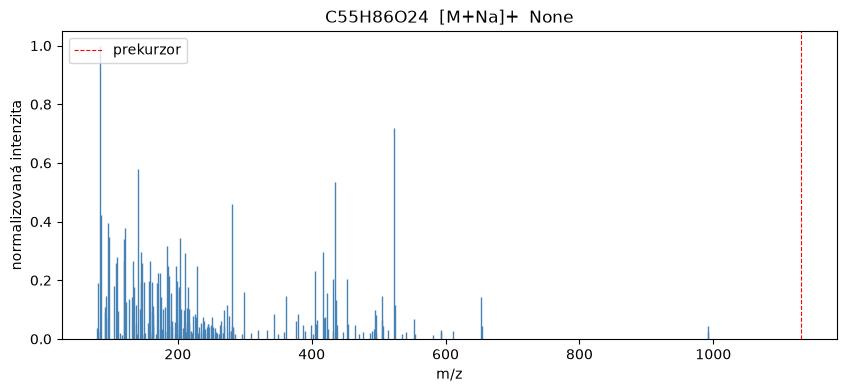

In [49]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4))
ax.vlines(mzs, 0, ints, color="steelblue", linewidth=1)
ax.axvline(s["precursor_mz"], color="red", linestyle="--", linewidth=0.8, label="prekurzor")

ax.set_xlabel("m/z")
ax.set_ylabel("normalizovaná intenzita")
ax.set_ylim(bottom=0)
ax.set_title(f'{s["molecular_formula"]}  {s["adduct"]}  {s["collision_energy_orig"]}')
ax.legend()
plt.show()
